In [1]:
from ccvtools import rawio
import imageio.v2 as iio
import numpy as np
from tqdm import tqdm

%matplotlib ipympl
import matplotlib.pyplot as plt 

In [2]:
files = [
    "H:/yamlsaving/aptina1.ccv",
    # "D:/yamlsaving/pylon1_1k.ccv"
]

In [3]:
framerate = 50

In [4]:
readers = [iio.get_reader(file) for file in files]
print("Number of frames: ", [len(r) for r in readers])

Number of frames:  [82]


In [5]:
# Read all timestamps from video files for further analysis
timestamps_all = []
fr_idxs_all = []
for i_c, r in enumerate(readers):
    timestamps = []
    fr_idxs = []
    for i_f in range(len(r)):
        md = readers[i_c].get_meta_data(i_f)
        timestamps.append(md["timestamp"])
        fr_idxs.append(md["index"])
    timestamps_all.append(np.array(timestamps))
    fr_idxs_all.append(np.array(fr_idxs))

==== Cam 0 ====
Maximum step in frame idx:  589830
Maximum and minimum local fps:  -2.114865710851677e+307 2.765641167829799e+307
Number of frames with local fps < 37/s 42


C:\Users\bbo_admin\AppData\Local\Temp\ipykernel_21356\84639573.py:7: RuntimeWarning: overflow encountered in divide
  print(f"Number of frames with local fps < {int(0.75*framerate)}/s", np.sum(1/np.diff(ts) < 0.75*framerate))


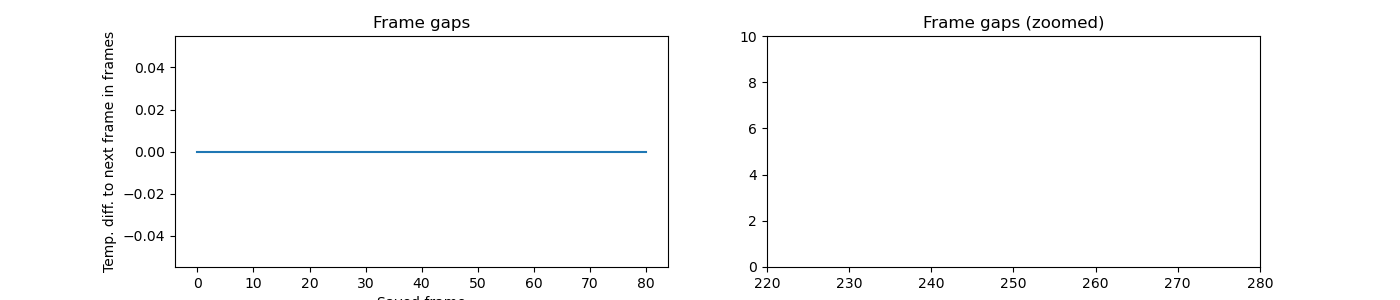

In [6]:
# Plot gaps between frames based on camera times
fig, axs = plt.subplots(1,2, figsize=(14,3))
for i_id, (ids, ts) in enumerate(zip(fr_idxs_all, timestamps_all)):
    print(f"==== Cam {i_id} ====")
    print("Maximum step in frame idx: ", np.max(np.diff(ids)))
    print("Maximum and minimum local fps: ", 1/np.min(np.diff(ts)), 1/np.max(np.diff(ts)))
    print(f"Number of frames with local fps < {int(0.75*framerate)}/s", np.sum(1/np.diff(ts) < 0.75*framerate))
    axs[0].plot(np.diff(ts)*framerate)
    axs[0].set_title("Frame gaps")
    axs[0].set_xlabel("Saved frame")
    axs[0].set_ylabel("Temp. diff. to next frame in frames")
    axs[1].plot(np.diff(ts)*framerate)
    axs[1].set_xlim((220,280))
    axs[1].set_ylim((0,10))
    axs[1].set_title("Frame gaps (zoomed)")
    axs[0].set_xlabel("Saved frame")

In [7]:
# Print first 10 saved frame idxs and cam times
for i_cam in range(len(files)):
    print("Cam ", i_cam)
    timestamps = []
    for i in range(10):
        md = readers[i_cam].get_meta_data(i)
        print(md)
        timestamps.append(md["timestamp"])
    timestamps = np.array(timestamps)
    print(np.diff(timestamps)/(1/framerate))

Cam  0
{'index': 3342388, 'timestamp': 8.622390380628315e-308}
{'index': 2424866, 'timestamp': 3.8939577673003972e-308}
{'index': 2228259, 'timestamp': 5.840980152463333e-308}
{'index': 2687014, 'timestamp': 4.728447467071795e-308}
{'index': 2228254, 'timestamp': 6.675378605735743e-308}
{'index': 2490406, 'timestamp': 4.450304746645715e-308}
{'index': 2162722, 'timestamp': 6.397278324901683e-308}
{'index': 2687006, 'timestamp': 5.00657321159631e-308}
{'index': 2555942, 'timestamp': 4.728434735356083e-308}
{'index': 2228264, 'timestamp': 5.562841675899314e-308}
[-2.36421631e-306  9.73511193e-307 -5.56266343e-307  9.73465569e-307
 -1.11253693e-306  9.73486789e-307 -6.95352557e-307 -1.39069238e-307
  4.17203470e-307]


IndexError: Image index %i > %i

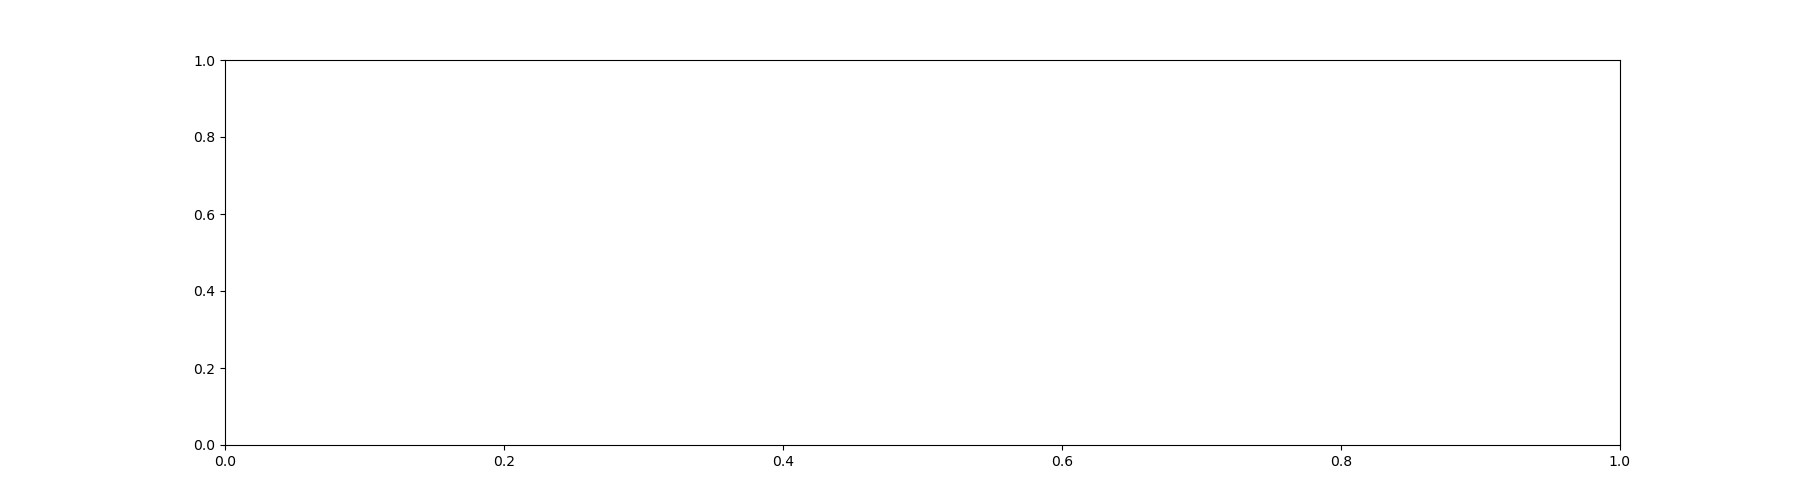

In [8]:
# Plot single frame from each cam
fig, axs = plt.subplots(1,len(files), figsize=(18,5), squeeze=False)
for ax,r in zip(axs[0],readers):
    ax.imshow(r.get_data(100))

In [9]:
# Print local frame rate
1/np.diff(timestamps)

C:\Users\bbo_admin\AppData\Local\Temp\ipykernel_21356\2171230936.py:2: RuntimeWarning: overflow encountered in divide
  1/np.diff(timestamps)


array([-2.11486571e+307,  5.13604778e+307, -8.98849996e+307,
        5.13628849e+307, -4.49423284e+307,  5.13617653e+307,
       -7.19059699e+307,             -inf,  1.19845599e+308])